In [5]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [9]:
class BatsmanState(TypedDict):
    
    runs: int
    balls: int
    fours: int
    sixes: int 
    
    sr: float
    bpb: float
    boundary_percent: float
    summery: str

In [17]:
def strike_rate(state: BatsmanState) -> BatsmanState:
    runs = state['runs']
    balls = state['balls']

    sr = (runs/balls)*100
    # state['sr'] = sr
    
    return {"sr": sr}

def balls_per_boundary(state: BatsmanState) -> BatsmanState:
    balls = state['balls']
    fours = state['fours']
    sixes = state['sixes']
    
    bpb = balls/(fours + sixes)
    
    # state['bpb'] = bpb
    
    return {"bpb": bpb}


def boundary_percent(state: BatsmanState) -> BatsmanState:
    fours = state["fours"]
    sixes = state["sixes"]
    runs = state['runs']

    bp = (((fours * 4) + (sixes * 6))/runs)*100
    
    # state['boundary_percent'] = bp
    
    return {"boundary_percent": bp}

def summery(state: BatsmanState) -> BatsmanState:
    sr = state['sr']
    bpb = state['bpb']
    bp = state['boundary_percent']
    
    final_summery = f"""
    Strike Rate -> {sr} \n
    Balls Per Boundary -> {bpb} \n
    Boundary Percent -> {bp} \n
    """
    
    # state['summery'] = final_summery
    
    return {"summery": final_summery}

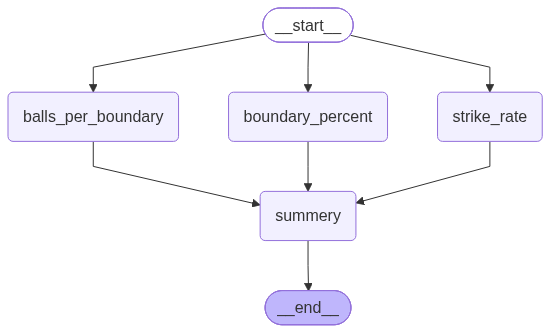

In [21]:
graph = StateGraph(BatsmanState)

# nodes
graph.add_node("strike_rate", strike_rate)
graph.add_node("balls_per_boundary", balls_per_boundary)
graph.add_node("boundary_percent", boundary_percent)
graph.add_node("summery", summery)

# edges
graph.add_edge(START, "strike_rate")
graph.add_edge(START, "balls_per_boundary")
graph.add_edge(START, "boundary_percent")

graph.add_edge("strike_rate", "summery")
graph.add_edge("balls_per_boundary", "summery")
graph.add_edge("boundary_percent", "summery")

graph.add_edge("summery", END)

# compile
workflow = graph.compile()
workflow

In [22]:
initial_state = {
    "runs": 100,
    "balls": 50,
    "fours": 6,
    "sixes": 5
}

final_state = workflow.invoke(initial_state)
final_state

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 5,
 'sr': 200.0,
 'bpb': 4.545454545454546,
 'boundary_percent': 54.0,
 'summery': '\n    Strike Rate -> 200.0 \n\n    Balls Per Boundary -> 4.545454545454546 \n\n    Boundary Percent -> 54.0 \n\n    '}